# Project Data Exploration: Relationships and Categorical Plots

We explore the Online News Popularity dataset using Seaborn scatter plots,
categorical plots, and small multiples. Run the cells in order with the CSV
beside this notebook; environment setup is in `README.md`.

**Group name:** Group 8</br>
**Created by:** Sandy Tam (017113655), Emily Liu (017073277), Chloe Pham (017160442)</br>
**Last updated:** 11/16/2026</br>
</br></br>
Our dataset contains information about 39,644 Mashable articles, including their length, topics, sentiment, images, and links. Its goal is to predict an article’s popularity, measured by its number of social media shares.

## Import data

In [1]:
# Optional: uncomment and run once if needed.
# %pip install pandas matplotlib seaborn scipy

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("OnlineNewsPopularity.csv")
df.columns = df.columns.str.strip()
sns.set_theme(style="whitegrid")
df.head()

,url,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
0,http://mashable.com/2013/01/07/amazon-instant-...,731.0,12.0,219.0,0.663594,1.0,0.815385,4.0,2.0,1.0,...,0.100000,0.7,-0.350000,-0.600,-0.200000,0.500000,-0.187500,0.000000,0.187500,593
1,http://mashable.com/2013/01/07/ap-samsung-spon...,731.0,9.0,255.0,0.604743,1.0,0.791946,3.0,1.0,1.0,...,0.033333,0.7,-0.118750,-0.125,-0.100000,0.000000,0.000000,0.500000,0.000000,711
2,http://mashable.com/2013/01/07/apple-40-billio...,731.0,9.0,211.0,0.575130,1.0,0.663866,3.0,1.0,1.0,...,0.100000,1.0,-0.466667,-0.800,-0.133333,0.000000,0.000000,0.500000,0.000000,1500
3,http://mashable.com/2013/01/07/astronaut-notre...,731.0,9.0,531.0,0.503788,1.0,0.665635,9.0,0.0,1.0,...,0.136364,0.8,-0.369697,-0.600,-0.166667,0.000000,0.000000,0.500000,0.000000,1200
4,http://mashable.com/2013/01/07/att-u-verse-apps/,731.0,13.0,1072.0,0.415646,1.0,0.540890,19.0,19.0,20.0,...,0.033333,1.0,-0.220192,-0.500,-0.050000,0.454545,0.136364,0.045455,0.136364,505


## Q1: Data background
Provide a brief summary of the data including source, size of data, topic, and what the motivation behind exploring this dataset.

The Online News Popularity dataset comes from the UCI Machine Learning
Repository and describes Mashable articles over a two-year period. Our CSV has
**39,644 articles and 61 original columns**, including article characteristics,
the URL, elapsed time, and the target `shares`.

We want to understand which characteristics are associated with social-media
sharing, including images, sentiment, category, and publication-day flags.
This can inform a popularity-prediction question, but these observational plots
cannot show that changing a characteristic causes an article to receive more shares.

### Q2: Show the number of missing data in each column of the dataframe
If you have missing data, how much? which column(s)? Do you think it will impact your output?

In [3]:
missing_values = df.isna().sum()
print(missing_values.to_string())
print(f"\nTotal missing values: {missing_values.sum()}")

url                              0
timedelta                        0
n_tokens_title                   0
n_tokens_content                 0
n_unique_tokens                  0
n_non_stop_words                 0
n_non_stop_unique_tokens         0
num_hrefs                        0
num_self_hrefs                   0
num_imgs                         0
num_videos                       0
average_token_length             0
num_keywords                     0
data_channel_is_lifestyle        0
data_channel_is_entertainment    0
data_channel_is_bus              0
data_channel_is_socmed           0
data_channel_is_tech             0
data_channel_is_world            0
kw_min_min                       0
kw_max_min                       0
kw_avg_min                       0
kw_min_max                       0
kw_max_max                       0
kw_avg_max                       0
kw_min_avg                       0
kw_max_avg                       0
kw_avg_avg                       0
self_reference_min_s

The original CSV has no missing values in any column. This does not rule out
invalid ranges or feature-extraction issues. P2 checks token ratios, zero content
lengths, and inconsistencies between URL dates and the supplied weekday flags.

### Q3: Show the data type for each column of the dataframe
Is the data type as expected? Is it clear what the content/value of each column is?

In [4]:
print(df.dtypes.to_string())

url                               object
timedelta                        float64
n_tokens_title                   float64
n_tokens_content                 float64
n_unique_tokens                  float64
n_non_stop_words                 float64
n_non_stop_unique_tokens         float64
num_hrefs                        float64
num_self_hrefs                   float64
num_imgs                         float64
num_videos                       float64
average_token_length             float64
num_keywords                     float64
data_channel_is_lifestyle        float64
data_channel_is_entertainment    float64
data_channel_is_bus              float64
data_channel_is_socmed           float64
data_channel_is_tech             float64
data_channel_is_world            float64
kw_min_min                       float64
kw_max_min                       float64
kw_avg_min                       float64
kw_min_max                       float64
kw_max_max                       float64
kw_avg_max      

The data type for each column is mostly expected and the content/value of each column can be clearly distinguished. For some columns, like num_imgs and num_videos, it could make more sense to convert them from float64 to integers since they represent whole number counts. Columns like the is_weekend and data_channel_is_lifestyle could also be converted from float64 to boolean as well.

### Q4: Your own question using `relplot()`
Come up with your own question to do the initital exploration of your data that utilizes the `relplot()` package to understand relationships between two variables.

**How is the number of images associated with article shares?**

A reproducible sample of 5,000 articles keeps the scatter plot readable, and a
logarithmic share axis reduces compression from viral articles. The full-data
Spearman correlation is about **0.083**, a weak positive monotonic association.
This does not imply that adding images causes more sharing.

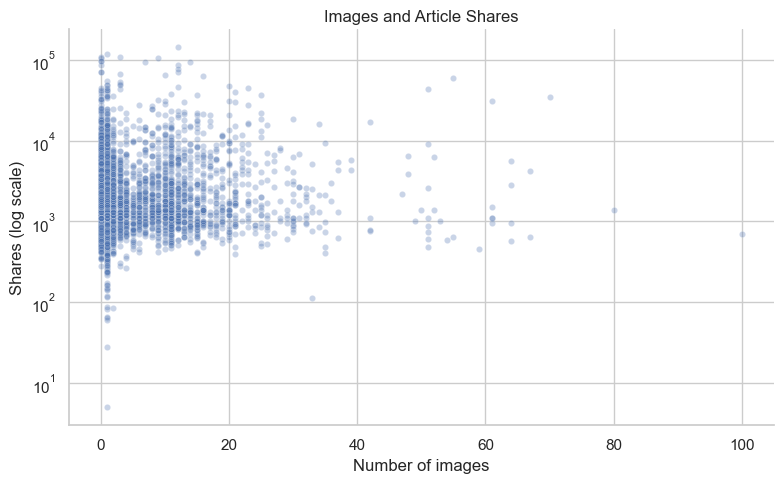

Full-data Spearman correlation: 0.083


In [5]:
plot = sns.relplot(
    data=df.sample(n=min(5000, len(df)), random_state=13),
    x="num_imgs", y="shares", kind="scatter", alpha=0.3,
    s=20, height=5, aspect=1.6,
)
plot.set(
    yscale="log", title="Images and Article Shares",
    xlabel="Number of images", ylabel="Shares (log scale)",
)
plt.tight_layout()
plt.show()
plt.close()
print("Full-data Spearman correlation:", round(df["num_imgs"].corr(df["shares"], method="spearman"), 3))

### Q5: `catplot()`
Do weekend articles have higher median shares than weekday articles?

Weekend articles have a median of **1,900 shares**, compared with **1,400** for
weekdays. We use the supplied weekend flag and compare medians rather than means
because shares are strongly skewed. This is an unadjusted association.

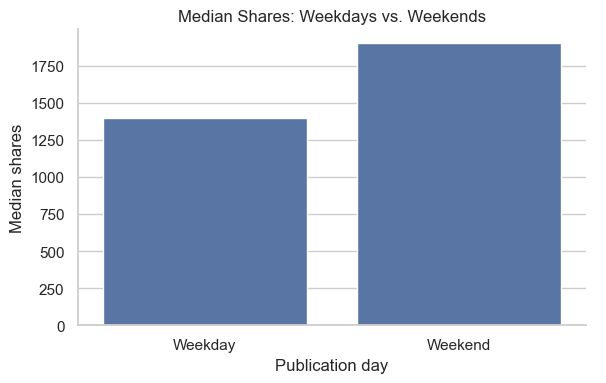

In [6]:
plot = sns.catplot(
    data=df, x="is_weekend", y="shares", kind="bar",
    estimator="median", errorbar=None, height=4, aspect=1.5,
)
plot.set(title="Median Shares: Weekdays vs. Weekends", xlabel="Publication day", ylabel="Median shares")
plot.set_xticklabels(["Weekday", "Weekend"])
plt.tight_layout()
plt.show()
plt.close()

### Q6: Small Multiples
**Within each article category, how is title subjectivity associated with shares,
excluding the highest-share articles?**

We display articles at or below the global 99th-percentile share count. This
explicit visualization cutoff changes the displayed population; it does not
remove observations from the source dataset. Each panel has height 5, point
size 20, and three panels per row as requested.

We use `title_subjectivity` to match the question, and label articles without
category flags **Other**. The panels overlap substantially in share counts;
there is no clear universal subjectivity-to-popularity rule in this visual check.

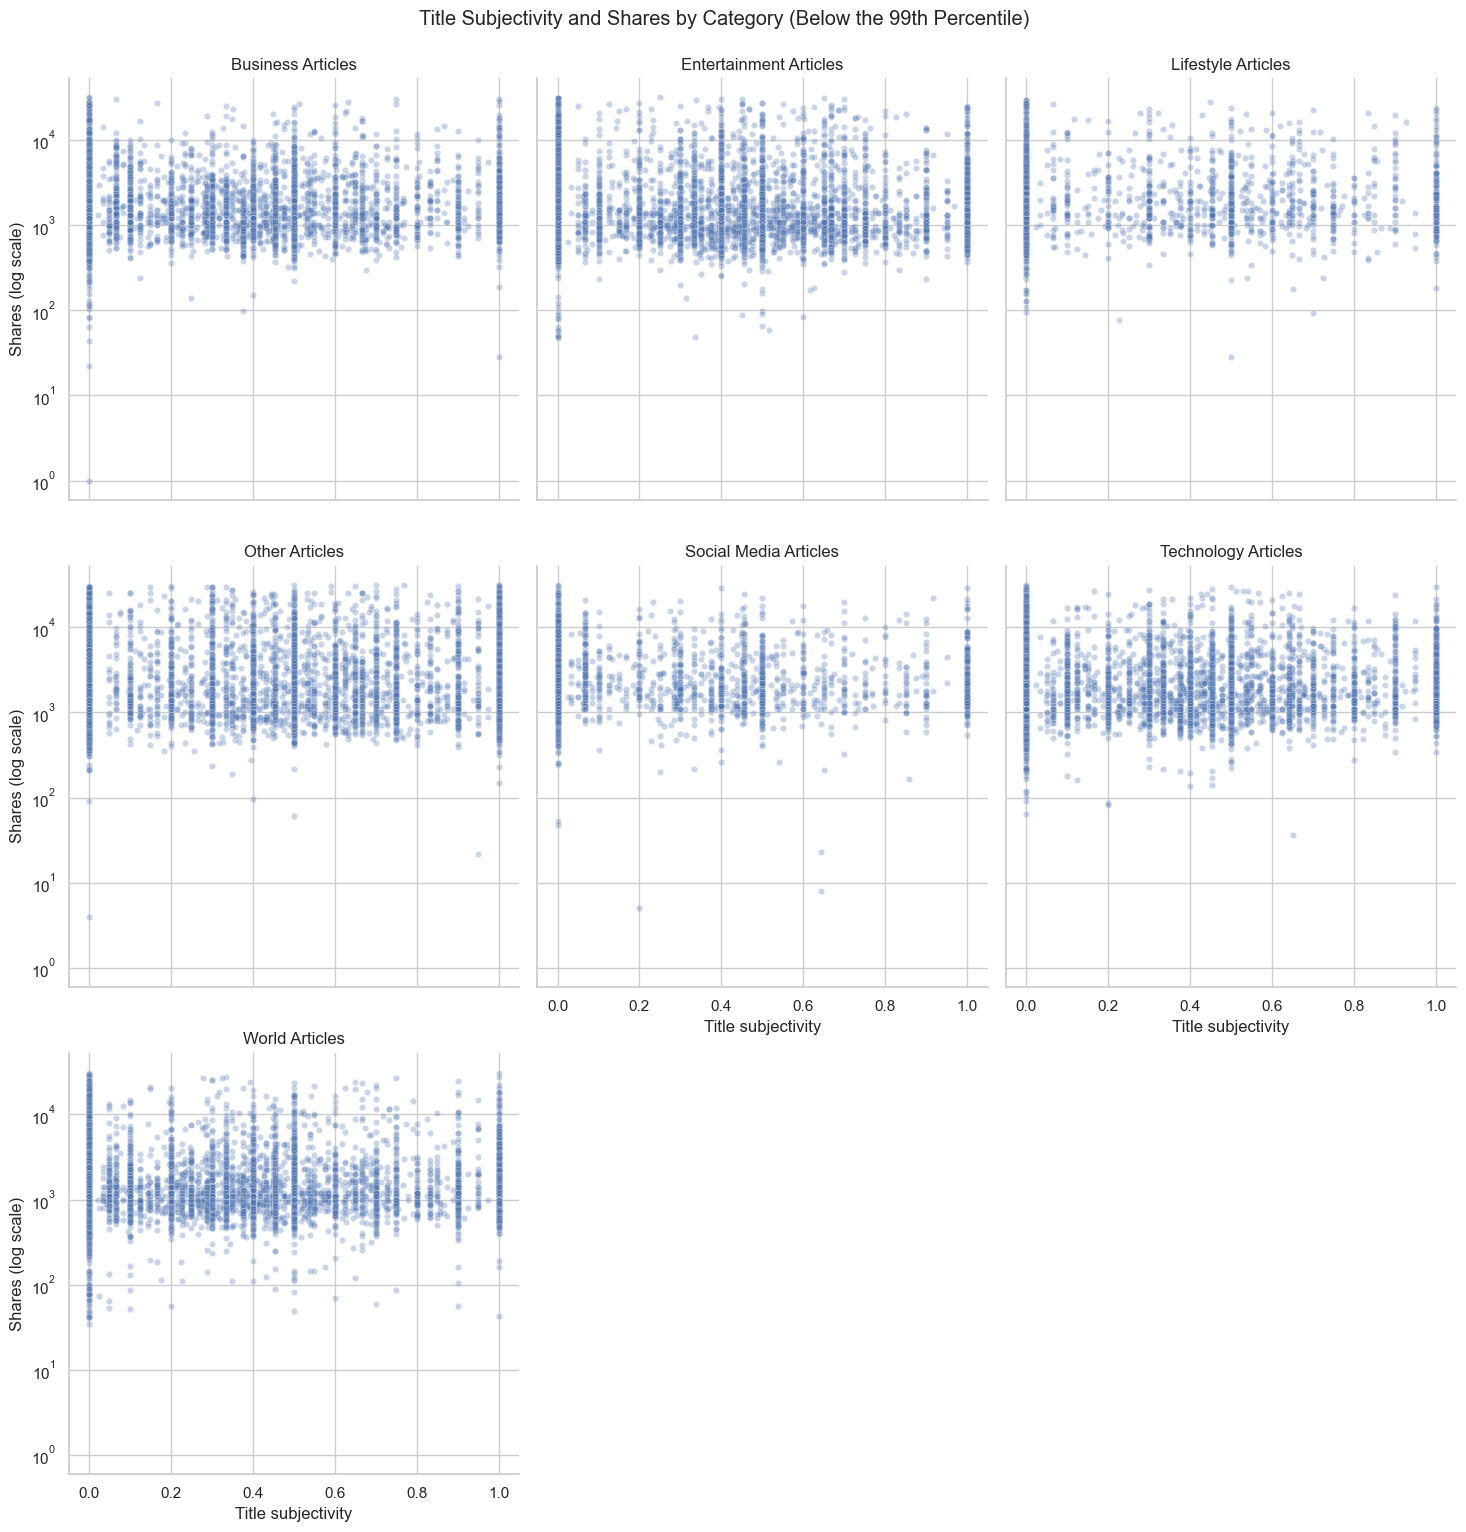

In [7]:
category_names = {
    "data_channel_is_lifestyle": "Lifestyle",
    "data_channel_is_entertainment": "Entertainment",
    "data_channel_is_bus": "Business",
    "data_channel_is_socmed": "Social Media",
    "data_channel_is_tech": "Technology",
    "data_channel_is_world": "World",
}
category_flags = df[list(category_names)]
df["article_category"] = category_flags.idxmax(axis=1).map(category_names)
df.loc[category_flags.sum(axis=1) == 0, "article_category"] = "Other"

share_99 = df["shares"].quantile(0.99)
plot_99 = df[df["shares"] <= share_99]
plot = sns.relplot(
    data=plot_99, x="title_subjectivity", y="shares", col="article_category",
    col_order=sorted(df["article_category"].unique()), col_wrap=3,
    kind="scatter", height=5, s=20, alpha=0.3,
)
plot.set(yscale="log")
plot.set_axis_labels("Title subjectivity", "Shares (log scale)")
plot.set_titles("{col_name} Articles")
plot.figure.suptitle("Title Subjectivity and Shares by Category (Below the 99th Percentile)", y=1.02)
plt.show()
plt.close()